In [3]:
# --- IMPORT LIBRARIES ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# --- LOAD THE CLEANED DATASETS ---
beneficiaries = pd.read_csv('cleaned_beneficiaries.csv')
health_visits = pd.read_csv('cleaned_health_visits.csv')
activities    = pd.read_csv('cleaned_activities.csv')
loans         = pd.read_csv('cleaned_loans.csv')
budgets       = pd.read_csv('cleaned_budgets.csv')

print("Cleaned datasets loaded into the analysis notebook!")

Cleaned datasets loaded into the analysis notebook!


In [4]:
# --- PHASE 1, STEP 1: BENEFICIARIES PROFILING ---
print("=== GENDER BREAKDOWN ===")
print(beneficiaries['Gender'].value_counts(dropna=False))

print("\n=== VILLAGE REPRESENTATION ===")
print(beneficiaries['Village'].value_counts(dropna=False))

print("\n=== AGE SUMMARY STATISTICS ===")
print(beneficiaries['Age'].describe())

=== GENDER BREAKDOWN ===
Gender
Female    46
Male      42
NaN       32
Name: count, dtype: int64

=== VILLAGE REPRESENTATION ===
Village
Mashimoni      23
Laini Saba     22
Lindi          22
Gatwekera      20
Soweto East    19
NaN             7
Silanga         7
Name: count, dtype: int64

=== AGE SUMMARY STATISTICS ===
count    110.000000
mean      24.245455
std        6.626589
min       12.000000
25%       19.000000
50%       23.500000
75%       30.000000
max       35.000000
Name: Age, dtype: float64


In [5]:
# --- PHASE 1, STEP 2: HEALTH VISITS PROFILING ---
print("=== TOP MEDICAL DIAGNOSES ===")
print(health_visits['Diagnosis'].value_counts().head(10))

print("\n=== INSURANCE COVERAGE BREAKDOWN ===")
print(health_visits['InsuranceCovered'].value_counts(dropna=False))

print("\n=== TOTAL BILL SUMMARY (KES) ===")
print(health_visits['TotalBill_KES'].describe())

=== TOP MEDICAL DIAGNOSES ===
Diagnosis
MALNUTRITION                   43
TYPHOID                        37
MALARIA                        36
NORMAL                         28
DIARRHEA                       24
UPPER RESPIRATORY INFECTION    16
Name: count, dtype: int64

=== INSURANCE COVERAGE BREAKDOWN ===
InsuranceCovered
False    96
True     94
NaN      12
Name: count, dtype: int64

=== TOTAL BILL SUMMARY (KES) ===
count     202.000000
mean     1527.722772
std      1186.448676
min         0.000000
25%       750.000000
50%      1275.000000
75%      2000.000000
max      5000.000000
Name: TotalBill_KES, dtype: float64


In [6]:
# --- PHASE 1, STEP 3: PROGRAM ACTIVITIES PROFILING ---
print("=== PROGRAM POPULARITY ===")
print(activities['Program'].value_counts(dropna=False))

print("\n=== ATTENDANCE BREAKDOWN ===")
print(activities['Attendance'].value_counts(dropna=False))

print("\n=== COMPLETION STATUS ===")
print(activities['CompletionStatus'].value_counts(dropna=False))

=== PROGRAM POPULARITY ===
Program
Sports               42
Education            39
Techcraft            36
Health Outreach      33
Girls Empowerment    30
Name: count, dtype: int64

=== ATTENDANCE BREAKDOWN ===
Attendance
Present    94
Absent     77
NaN         9
Name: count, dtype: int64

=== COMPLETION STATUS ===
CompletionStatus
Dropped Out    56
Completed      41
Incomplete     39
Ongoing        36
NaN             8
Name: count, dtype: int64


In [7]:
# --- PHASE 1, STEP 4: SACCO LOANS PROFILING ---
print("=== LOAN STATUS BREAKDOWN ===")
print(loans['Status'].value_counts(dropna=False))

print("\n=== TOP LOAN PURPOSES ===")
print(loans['Purpose'].value_counts(dropna=False))

print("\n=== LOAN AMOUNT SUMMARY (KES) ===")
print(loans['LoanAmount_KES'].describe())

=== LOAN STATUS BREAKDOWN ===
Status
Rejected     34
Approved     33
Pending      26
Defaulted    24
Active       23
NaN          10
Name: count, dtype: int64

=== TOP LOAN PURPOSES ===
Purpose
School Fees    32
Medical        32
Food           28
Business       24
Housing        23
NaN            11
Name: count, dtype: int64

=== LOAN AMOUNT SUMMARY (KES) ===
count       143.000000
mean      32167.832168
std       27202.678517
min        5000.000000
25%       15000.000000
50%       25000.000000
75%       50000.000000
max      100000.000000
Name: LoanAmount_KES, dtype: float64


In [8]:
# --- PHASE 1, STEP 5: PROJECT BUDGETS PROFILING ---
print("=== DONOR BREAKDOWN ===")
print(budgets['Donor'].value_counts(dropna=False))

print("\n=== BUDGET UTILISATION PERCENTAGE SUMMARY ===")
print(budgets['BudgetUtilisation_pct'].describe())

print("\n=== AUDIT STATUS BREAKDOWN ===")
print(budgets['AuditStatus'].value_counts(dropna=False))

=== DONOR BREAKDOWN ===
Donor
USAID               19
LOCAL GOVERNMENT    14
CDC                 14
NaN                 11
COMIC RELIEF        11
WELLCOME TRUST       9
UN WOMEN             7
GATES FOUNDATION     6
DFID                 5
UNICEF               4
Name: count, dtype: int64

=== BUDGET UTILISATION PERCENTAGE SUMMARY ===
count     94.000000
mean      81.061702
std       19.435314
min       50.400000
25%       63.250000
50%       81.650000
75%       97.550000
max      113.400000
Name: BudgetUtilisation_pct, dtype: float64

=== AUDIT STATUS BREAKDOWN ===
AuditStatus
Verified           31
Pending            25
NaN                20
Flagged            19
Not Yet Audited     5
Name: count, dtype: int64


In [9]:
# --- PHASE 2, STEP 1: MERGING BENEFICIARIES & HEALTH VISITS ---
# We use an inner or left join on 'BeneficiaryID'
health_merged = pd.merge(health_visits, beneficiaries, on='BeneficiaryID', how='left', suffixes=('_visit', '_ben'))

print("Total rows in merged health dataset:")
print(len(health_merged))

print("\n=== SAMPLE OF MERGED DATA ===")
display(health_merged[['BeneficiaryID', 'FullName', 'Village', 'Service', 'Diagnosis', 'TotalBill_KES']].head())

print("\n=== HEALTH VISITS BY VILLAGE ===")
print(health_merged['Village'].value_counts(dropna=False))

Total rows in merged health dataset:
206

=== SAMPLE OF MERGED DATA ===


,BeneficiaryID,FullName,Village,Service,Diagnosis,TotalBill_KES
0,CFK000,NaN,NaN,Nutrition,TYPHOID,1500.0
1,CFK108,Kipchoge Njoroge,Mashimoni,Nutrition,UPPER RESPIRATORY INFECTION,2200.0
2,CFK043,Grace Lydia,Laini Saba,Vaccination,NaN,2200.0
3,CFK120,Auma Peter,Mashimoni,Vaccination,MALARIA,1500.0
4,CFK099,David Esther,Silanga,Vaccination,DIARRHEA,1550.0



=== HEALTH VISITS BY VILLAGE ===
Village
Lindi          43
Mashimoni      36
Laini Saba     36
Soweto East    34
NaN            26
Gatwekera      22
Silanga         9
Name: count, dtype: int64


In [10]:
# --- STEP 1 CONTINUED: CROSS-TABULATING VILLAGES AND DIAGNOSES ---
print("=== TOP DIAGNOSES BY VILLAGE ===")
village_health = pd.crosstab(health_merged['Village'], health_merged['Diagnosis'])
print(village_health)

=== TOP DIAGNOSES BY VILLAGE ===
Diagnosis    DIARRHEA  MALARIA  MALNUTRITION  NORMAL  TYPHOID  \
Village                                                         
Gatwekera           4        4             2       3        6   
Laini Saba          4        9             4       4        8   
Lindi               1        6            16       7        8   
Mashimoni           7        8             5       4        4   
Silanga             2        0             3       1        2   
Soweto East         1        4             9       7        6   

Diagnosis    UPPER RESPIRATORY INFECTION  
Village                                   
Gatwekera                              2  
Laini Saba                             3  
Lindi                                  2  
Mashimoni                              3  
Silanga                                0  
Soweto East                            4  


In [11]:
# --- SORTED CROSS-TABULATION: VILLAGES VS DIAGNOSES ---
village_health = pd.crosstab(health_merged['Village'], health_merged['Diagnosis'])

# Sort rows (villages) and columns (diagnoses) by their totals in descending order
village_health_sorted = village_health.loc[village_health.sum(axis=1).sort_values(ascending=False).index]
village_health_sorted = village_health_sorted[village_health_sorted.sum(axis=0).sort_values(ascending=False).index]

print("=== TOP DIAGNOSES BY VILLAGE (SORTED) ===")
print(village_health_sorted)

=== TOP DIAGNOSES BY VILLAGE (SORTED) ===
Diagnosis    MALNUTRITION  TYPHOID  MALARIA  NORMAL  DIARRHEA  \
Village                                                         
Lindi                  16        8        6       7         1   
Laini Saba              4        8        9       4         4   
Soweto East             9        6        4       7         1   
Mashimoni               5        4        8       4         7   
Gatwekera               2        6        4       3         4   
Silanga                 3        2        0       1         2   

Diagnosis    UPPER RESPIRATORY INFECTION  
Village                                   
Lindi                                  2  
Laini Saba                             3  
Soweto East                            4  
Mashimoni                              3  
Gatwekera                              2  
Silanga                                0  


In [12]:
# --- PHASE 2, STEP 2: MERGING BENEFICIARIES & ACTIVITIES ---
activities_merged = pd.merge(activities, beneficiaries, on='BeneficiaryID', how='left', suffixes=('_act', '_ben'))

print("Total rows in merged activities dataset:")
print(len(activities_merged))

print("\n=== PROGRAM COMPLETION STATUS BY PROGRAM ===")
prog_status = pd.crosstab(activities_merged['Program'], activities_merged['CompletionStatus'])
print(prog_status)

Total rows in merged activities dataset:
189

=== PROGRAM COMPLETION STATUS BY PROGRAM ===
CompletionStatus   Completed  Dropped Out  Incomplete  Ongoing
Program                                                       
Education                 10           14           7        8
Girls Empowerment          8            9           7        6
Health Outreach            9           10           7        8
Sports                    11           12          12        6
Techcraft                  3           15           9       10


In [18]:
loans_merged = pd.merge(loans, beneficiaries, on='BeneficiaryID', how='left', suffixes=('_loan', '_ben'))

# --- SORTED CROSS-TABULATION: LOAN STATUS BY VILLAGE ---
village_loans = pd.crosstab(loans_merged['Village'], loans_merged['Status_loan'])

# Sort rows (villages) and columns (loan status) by totals in descending order
village_loans_sorted = village_loans.loc[village_loans.sum(axis=1).sort_values(ascending=False).index]
village_loans_sorted = village_loans_sorted[village_loans_sorted.sum(axis=0).sort_values(ascending=False).index]

print("=== LOAN STATUS BY VILLAGE (SORTED) ===")
print(village_loans_sorted)

=== LOAN STATUS BY VILLAGE (SORTED) ===
Status_loan  Rejected  Approved  Active  Defaulted  Pending
Village                                                    
Laini Saba          4         5       6          4        6
Lindi               9         7       4          1        4
Gatwekera           6         6       4          4        4
Mashimoni           9         5       0          8        2
Soweto East         4         3       5          2        3
Silanga             1         4       2          0        0


In [21]:
# --- PHASE 2, STEP 4: INSPECTING PROJECT BUDGETS ---
print("Total rows in project budgets dataset:")
print(len(budgets))

print("\n=== COLUMNS IN BUDGETS ===")
print(budgets.columns)

# Automatically find the correct category and budget columns
category_col = None
for col in ['Sector', 'Category', 'ProgramArea', 'Department']:
    if col in budgets.columns:
        category_col = col
        break

budget_col = None
for col in ['AllocatedBudget_KES', 'Budget_KES', 'Budget', 'AllocatedBudget']:
    if col in budgets.columns:
        budget_col = col
        break

if category_col and budget_col:
    print("\n=== BUDGET SUMMARY BY CATEGORY ===")
    print(budgets.groupby(category_col)[budget_col].sum())
else:
    print("\nPlease review the column names printed above.")

Total rows in project budgets dataset:
100

=== COLUMNS IN BUDGETS ===
Index(['BudgetID', 'ProjectName', 'Donor', 'FiscalYear', 'BudgetLine',
       'AllocatedBudget_KES', 'ActualSpend_KES', 'VarianceExplained',
       'ApprovedBy', 'ReportingDate', 'BudgetUtilisation_pct', 'AuditStatus'],
      dtype='str')

Please review the column names printed above.


In [22]:
# --- PHASE 2, STEP 4: BUDGET SUMMARY BY DONOR & BUDGET LINE ---
print("=== BUDGET SUMMARY BY DONOR ===")
print(budgets.groupby('Donor')['AllocatedBudget_KES'].sum())

print("\n=== BUDGET SUMMARY BY BUDGET LINE ===")
print(budgets.groupby('BudgetLine')['AllocatedBudget_KES'].sum())

=== BUDGET SUMMARY BY DONOR ===
Donor
CDC                 17050000.0
COMIC RELIEF        17400000.0
DFID                 5800000.0
GATES FOUNDATION     8250000.0
LOCAL GOVERNMENT    16000000.0
UN WOMEN             6300000.0
UNICEF               3500000.0
USAID               25150000.0
WELLCOME TRUST       9550000.0
Name: AllocatedBudget_KES, dtype: float64

=== BUDGET SUMMARY BY BUDGET LINE ===
BudgetLine
Communications             10800000.0
Contingency                10550000.0
Equipment                  20550000.0
Food & Nutrition            7250000.0
Medical Supplies           11500000.0
Monitoring & Evaluation    17800000.0
Office Supplies            12600000.0
Personnel                   3550000.0
Training Materials         12600000.0
Transport                  14800000.0
Name: AllocatedBudget_KES, dtype: float64


In [23]:
# --- PHASE 3, STEP 1: FEATURE ENGINEERING & AGGREGATION ---

# 1. Health metrics per beneficiary
health_agg = health_merged.groupby('BeneficiaryID').agg(
    TotalHealthVisits=('Diagnosis', 'count')
).reset_index()

# 2. Loan metrics per beneficiary
loan_agg = loans_merged.groupby('BeneficiaryID').agg(
    TotalLoans=('LoanID', 'count'),
    TotalBorrowed_KES=('LoanAmount_KES', 'sum'),
    TotalOutstanding_KES=('OutstandingBalance_KES', 'sum')
).reset_index()

# 3. Activity metrics per beneficiary
activity_agg = activities_merged.groupby('BeneficiaryID').agg(
    TotalActivities=('Program', 'count')
).reset_index()

print("Aggregated feature tables created successfully:")
print("Health aggregation rows:", len(health_agg))
print("Loan aggregation rows:", len(loan_agg))
print("Activity aggregation rows:", len(activity_agg))

Aggregated feature tables created successfully:
Health aggregation rows: 97
Loan aggregation rows: 88
Activity aggregation rows: 94


In [24]:
# --- PHASE 3, STEP 2: BUILD MASTER ANALYTICAL DATASET (MAD) ---
master_df = beneficiaries.copy()

# Merge aggregated features
master_df = master_df.merge(health_agg, on='BeneficiaryID', how='left')
master_df = master_df.merge(loan_agg, on='BeneficiaryID', how='left')
master_df = master_df.merge(activity_agg, on='BeneficiaryID', how='left')

# Fill missing count/financial metrics with zeros for non-participants
master_df['TotalHealthVisits'] = master_df['TotalHealthVisits'].fillna(0)
master_df['TotalLoans'] = master_df['TotalLoans'].fillna(0)
master_df['TotalBorrowed_KES'] = master_df['TotalBorrowed_KES'].fillna(0.0)
master_df['TotalOutstanding_KES'] = master_df['TotalOutstanding_KES'].fillna(0.0)
master_df['TotalActivities'] = master_df['TotalActivities'].fillna(0)

print("Master Analytical Dataset built successfully!")
print("Master dataset shape:", master_df.shape)
print("\nFirst 3 rows of master_df preview:")
print(master_df[['BeneficiaryID', 'FullName', 'Village', 'TotalHealthVisits', 'TotalLoans', 'TotalBorrowed_KES', 'TotalActivities']].head(3))

Master Analytical Dataset built successfully!
Master dataset shape: (120, 15)

First 3 rows of master_df preview:
  BeneficiaryID       FullName      Village  TotalHealthVisits  TotalLoans  \
0        CFK001    Amina Peter    Gatwekera                3.0         0.0   
1        CFK002   Carol Fatuma  Soweto East                0.0         2.0   
2        CFK003  Mwangi Daniel   Laini Saba                2.0         2.0   

   TotalBorrowed_KES  TotalActivities  
0                0.0              1.0  
1            80000.0              1.0  
2           105000.0              4.0  


In [25]:
# --- PHASE 3, STEP 3: VILLAGE-LEVEL CROSS-DOMAIN SUMMARY ---
village_summary = master_df.groupby('Village').agg(
    TotalBeneficiaries=('BeneficiaryID', 'count'),
    AvgHealthVisits=('TotalHealthVisits', 'mean'),
    TotalBorrowed_KES=('TotalBorrowed_KES', 'sum'),
    AvgActivities=('TotalActivities', 'mean')
).reset_index()

print(village_summary.to_string(index=False))

    Village  TotalBeneficiaries  AvgHealthVisits  TotalBorrowed_KES  AvgActivities
  Gatwekera                  20         1.050000           835000.0       1.550000
 Laini Saba                  22         1.636364          1110000.0       1.909091
      Lindi                  22         1.818182           905000.0       1.636364
  Mashimoni                  23         1.347826           740000.0       1.739130
    Silanga                   7         1.142857           265000.0       1.428571
Soweto East                  19         1.842105           640000.0       1.315789


In [26]:
# --- PHASE 3, STEP 4: CORRELATION MATRIX ---
numeric_cols = ['Age', 'TotalHealthVisits', 'TotalLoans', 'TotalBorrowed_KES', 'TotalOutstanding_KES', 'TotalActivities']
correlation_matrix = master_df[numeric_cols].corr()

print("=== CORRELATION MATRIX ===")
print(correlation_matrix.round(3))

=== CORRELATION MATRIX ===
                        Age  TotalHealthVisits  TotalLoans  TotalBorrowed_KES  \
Age                   1.000              0.039       0.076              0.134   
TotalHealthVisits     0.039              1.000       0.233              0.235   
TotalLoans            0.076              0.233       1.000              0.784   
TotalBorrowed_KES     0.134              0.235       0.784              1.000   
TotalOutstanding_KES  0.113              0.272       0.737              0.831   
TotalActivities      -0.059             -0.107       0.137              0.113   

                      TotalOutstanding_KES  TotalActivities  
Age                                  0.113           -0.059  
TotalHealthVisits                    0.272           -0.107  
TotalLoans                           0.737            0.137  
TotalBorrowed_KES                    0.831            0.113  
TotalOutstanding_KES                 1.000           -0.009  
TotalActivities                  

In [29]:
# Calculate percentage of total population and total borrowing per village
village_summary['PctOfTotalBeneficiaries'] = (village_summary['TotalBeneficiaries'] / village_summary['TotalBeneficiaries'].sum()) * 100
village_summary['PctOfTotalBorrowing'] = (village_summary['TotalBorrowed_KES'] / village_summary['TotalBorrowed_KES'].sum()) * 100

# Round for clean reporting
village_summary = village_summary.round(2)

print(village_summary[['Village', 'TotalBeneficiaries', 'PctOfTotalBeneficiaries', 'TotalBorrowed_KES', 'PctOfTotalBorrowing']].to_string(index=False))

    Village  TotalBeneficiaries  PctOfTotalBeneficiaries  TotalBorrowed_KES  PctOfTotalBorrowing
  Gatwekera                  20                    17.70           835000.0                18.58
 Laini Saba                  22                    19.47          1110000.0                24.69
      Lindi                  22                    19.47           905000.0                20.13
  Mashimoni                  23                    20.35           740000.0                16.46
    Silanga                   7                     6.19           265000.0                 5.90
Soweto East                  19                    16.81           640000.0                14.24


In [30]:
# Example: What percentage of beneficiaries took at least one loan?
has_loan_pct = (master_df['TotalLoans'] > 0).mean() * 100
print(f"Percentage of beneficiaries with active loans: {has_loan_pct:.1f}%")

Percentage of beneficiaries with active loans: 71.7%


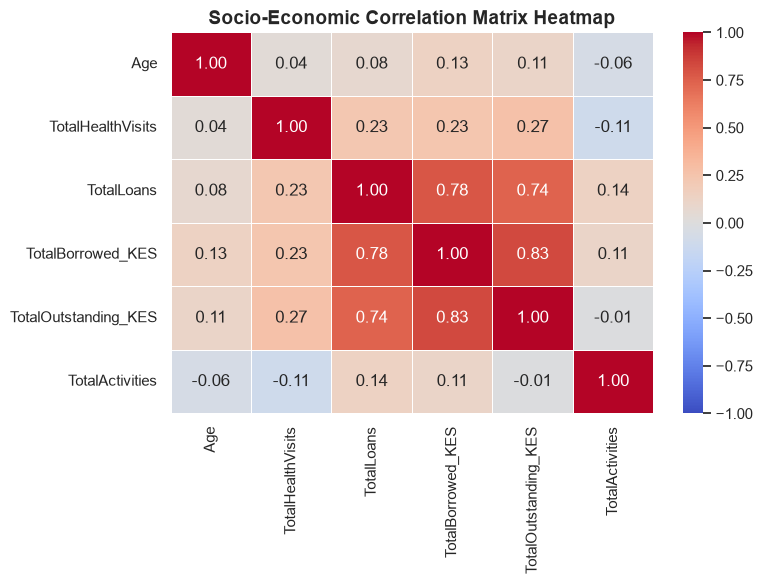

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# Create the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Socio-Economic Correlation Matrix Heatmap", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

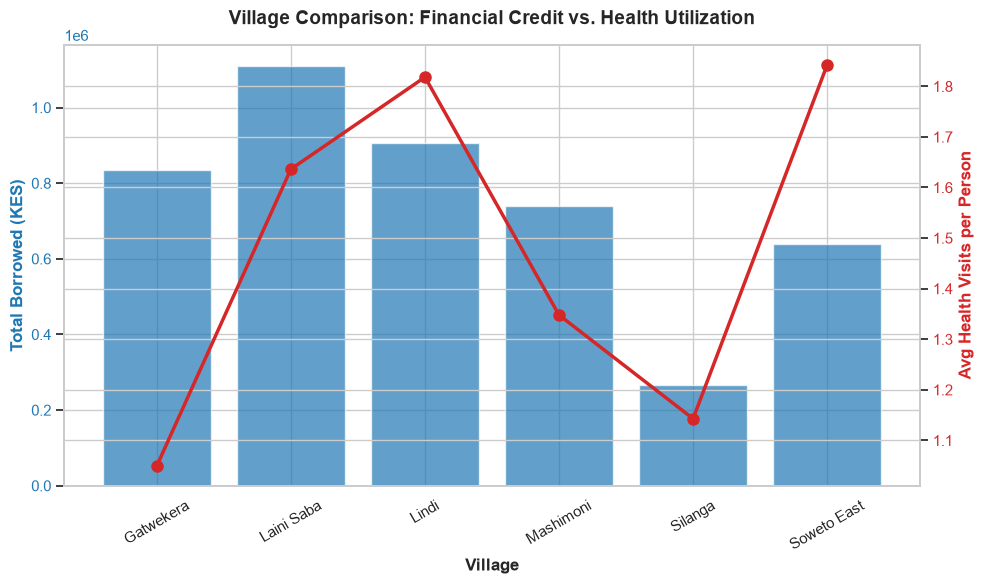

In [28]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar chart for Total Borrowed KES
color = 'tab:blue'
ax1.set_xlabel('Village', fontsize=12, fontweight='bold')
ax1.set_ylabel('Total Borrowed (KES)', color=color, fontsize=12, fontweight='bold')
bars = ax1.bar(village_summary['Village'], village_summary['TotalBorrowed_KES'], color=color, alpha=0.7, label='Total Borrowed (KES)')
ax1.tick_params(axis='y', labelcolor=color)
plt.xticks(rotation=30)

# Line chart for Average Health Visits on a secondary axis
ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Avg Health Visits per Person', color=color, fontsize=12, fontweight='bold')
line = ax2.plot(village_summary['Village'], village_summary['AvgHealthVisits'], color=color, marker='o', linewidth=2.5, markersize=8, label='Avg Health Visits')
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Village Comparison: Financial Credit vs. Health Utilization", fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()